# Genetic Algorithm for TSP

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(7)
n_cities = 20
city_names = list("ABCDEFGHIJKLMNOPQRST")
coords = rng.integers(0, 100, size=(n_cities, 2))
dist = np.linalg.norm(coords[:, None] - coords[None, :], axis=2)

population_size = 100
generations = 300
crossover_rate = 0.9
mutation_rate = 0.2

In [3]:
def route_distance(route):
    return sum(dist[route[i], route[(i + 1) % n_cities]] for i in range(n_cities))

def fitness(route):
    return 1 / route_distance(route)

def tournament(pop, k=3):
    return min(random.sample(pop, k), key=route_distance)

def ordered_crossover(p1, p2):
    a, b = sorted(random.sample(range(n_cities), 2))
    child = [None] * n_cities
    child[a:b + 1] = p1[a:b + 1]
    rest = [c for c in p2 if c not in child]
    for i in range(n_cities):
        if child[i] is None:
            child[i] = rest.pop(0)
    return child

def swap_mutation(route):
    i, j = random.sample(range(n_cities), 2)
    route[i], route[j] = route[j], route[i]
    return route

In [4]:
def genetic_algorithm(pop_size, gens, cx_rate, mut_rate, seed=42, elite=2):
    random.seed(seed)
    pop = [random.sample(range(n_cities), n_cities) for _ in range(pop_size)]
    history = []
    for _ in range(gens):
        pop.sort(key=route_distance)
        history.append(route_distance(pop[0]))
        new_pop = [r[:] for r in pop[:elite]]
        while len(new_pop) < pop_size:
            p1, p2 = tournament(pop), tournament(pop)
            child = ordered_crossover(p1, p2) if random.random() < cx_rate else p1[:]
            if random.random() < mut_rate:
                child = swap_mutation(child)
            new_pop.append(child)
        pop = new_pop
    best = min(pop, key=route_distance)
    history.append(route_distance(best))
    return best, history

In [5]:
best_route, history = genetic_algorithm(population_size, generations, crossover_rate, mutation_rate)

print("Best Route      :", " -> ".join(city_names[i] for i in best_route + [best_route[0]]))
print(f"Minimum Distance: {route_distance(best_route):.3f}")
print(f"Best Fitness    : {fitness(best_route):.6f}")

Best Route      : E -> L -> O -> M -> G -> D -> K -> N -> A -> P -> S -> R -> B -> C -> H -> Q -> T -> F -> I -> J -> E
Minimum Distance: 419.748
Best Fitness    : 0.002382


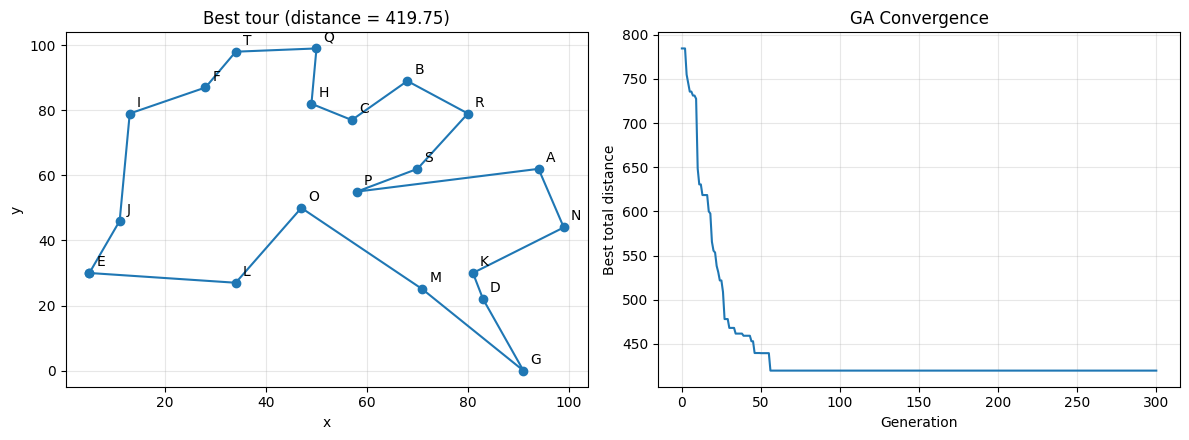

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

closed = best_route + [best_route[0]]
ax[0].plot(coords[closed, 0], coords[closed, 1], "o-")
for i, name in enumerate(city_names):
    ax[0].annotate(name, coords[i], xytext=(5, 5), textcoords="offset points")
ax[0].set_title(f"Best tour (distance = {route_distance(best_route):.2f})")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")

ax[1].plot(history)
ax[1].set_xlabel("Generation")
ax[1].set_ylabel("Best total distance")
ax[1].set_title("GA Convergence")

for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
settings = [
    ("Population Size", "100", "20", dict(pop_size=20)),
    ("Generations", "300", "30", dict(gens=30)),
    ("Crossover Rate", "0.90", "0.50", dict(cx_rate=0.5)),
    ("Mutation Rate", "0.20", "0.60", dict(mut_rate=0.6)),
]
base = dict(pop_size=population_size, gens=generations, cx_rate=crossover_rate, mut_rate=mutation_rate)
orig = route_distance(best_route)
rows = []
for name, old, new, change in settings:
    r, _ = genetic_algorithm(**{**base, **change})
    d = route_distance(r)
    rows.append([name, old, new, f"{orig:.3f}", f"{d:.3f}", f"{1 / d:.6f}"])
table = pd.DataFrame(rows, columns=["Parameter", "Original", "Modified", "Original Distance", "Modified Distance", "Modified Fitness"])
table

,Parameter,Original,Modified,Original Distance,Modified Distance,Modified Fitness
0,Population Size,100,20,419.748,483.980,0.002066
1,Generations,300,30,419.748,468.105,0.002136
2,Crossover Rate,0.90,0.50,419.748,471.736,0.002120
3,Mutation Rate,0.20,0.60,419.748,413.023,0.002421
